# Bot detection

### Full pr_comments dataset

In [ ]:
import pandas as pd

# Loading pr_comments.parquet
pr_comments = pd.read_parquet("Data/pr_comments.parquet")

# Filter user_type=="User"
user_filter = pr_comments['user_type'] == "User"

# Filter potential bots by username
bot_like_filter = pr_comments['user'].str.contains(r'bot|ci|copilot|ai|automation', case=False, na=False)

# Combine filters
suspected_bots = pr_comments[user_filter & bot_like_filter]

# Count the number of comments for each user
bot_counts = suspected_bots['user'].value_counts()

# Filter those who have a minimum of 10 comments
bot_counts_10plus = bot_counts[bot_counts >= 10]

# Sort records by comment count
bot_counts_10plus_sorted = bot_counts_10plus.sort_values(ascending=False)

# Display the first 50 suspects
display(bot_counts_10plus.head(50))

# Find Bots and change to BotOther
bots_users = ['CLAassistant', 'codecov-commenter', 'pytorchmergebot', 'k8s-ci-robot', 'robobun', 'wolfSSL-Bot', 'vdaas-ci', 'lightdash-bot', 'typescript-bot', 'calcom-bot', 'azure-sdk', 'owidbot', 'modularbot', 'facebook-github-bot','pulumi-bot','raycastbot']
pr_comments.loc[pr_comments['user'].isin(bots_users), 'user_type'] = 'BotOther'

user
captainsafia       52
jakebailey         48
ian-at-airbyte     34
NoritakaIkeda      32
k8s-ci-robot       28
MayaRainer         27
wolfSSL-Bot        25
vdaas-ci           25
jairmyree          15
hairyhum           13
raineorshine       13
takenagain         12
pytorchmergebot    11
aishwaryabh        11
owidbot            10
Name: count, dtype: int64

### Full pr_comments dataset - weaker bots_filter

In [2]:
filter = pr_comments['user_type']=='User'
bots_filter = pr_comments['user'].str.contains("bot")

display(pr_comments[filter& bots_filter]['user'].value_counts())
display(pr_comments[filter]['user'].value_counts()[:50])

bots_users =  ['CLAassistant', 'codecov-commenter', 'pytorchmergebot', 'k8s-ci-robot', 'robobun', 'wolfSSL-Bot', 'vdaas-ci', 'lightdash-bot', 'typescript-bot', 'calcom-bot', 'azure-sdk', 'owidbot', 'modularbot','facebook-github-bot','pulumi-bot','raycastbot']

pr_comments[pr_comments['user'].isin(bots_users)]

pr_comments.loc[pr_comments['user'].isin(bots_users), 'user_type'] = 'BotOther'

user
metamaskbot                   9
k8s-infra-cherrypick-robot    4
zwave-js-bot                  4
Issues-translate-bot          2
slangbot                      2
gravity-ui-bot                2
botberry                      2
gradio-pr-bot                 2
nf-core-bot                   2
mm-cloud-bot                  1
sre-ci-robot                  1
pyvista-bot                   1
throbotaith                   1
wheelsbot7                    1
istio-policy-bot              1
bits-bot                      1
Name: count, dtype: int64

user
joaomdmoura                            264
davidfowl                              161
anupriya13                             153
PureWeen                               144
slavingia                              132
coveralls                              129
benbalter                              108
vs-mobiletools-engineering-service2     86
mitchdenny                              84
marrobi                                 79
harupy                                  70
tomhrr                                  70
pierrevalade                            69
parseplatformorg                        67
jcstein                                 64
transphorm                              58
shige                                   56
pelikhan                                53
T-Gro                                   52
captainsafia                            52
brianrob                                52
JoshLove-msft                           51
meganrogge                              50
aarons

# Empty PRs

In [ ]:
# Loading all PRs from the full dataset
all_pr_df = pd.read_parquet("Data/pull_request.parquet")

# List all
all_pr_ids = all_pr_df["id"].unique()

# PRs with comments
prs_with_comments = pr_comments["pr_id"].unique()

# PRs without comments
prs_no_comments = set(all_pr_ids) - set(prs_with_comments)

len(prs_no_comments)

20621

# Split of PR reviews based on who performs the review

In [5]:
types_per_pr = (
    pr_comments.groupby("pr_id")["user_type"]
      .apply(lambda s: tuple(sorted(set(s))))
      .reset_index(name="type_set")
)

# Count PRs for each set of types
distribution = types_per_pr["type_set"].value_counts()

print(distribution)

print("\n\n# Reviews without human factor")
distribution[distribution.index.map(lambda t: 'User' in t)].sum()/distribution.sum()

type_set
(Bot,)                   7625
(Bot, User)              3749
(User,)                  1066
(BotOther,)               191
(Bot, BotOther, User)     143
(Bot, BotOther)           142
(BotOther, User)           59
Name: count, dtype: int64


# Reviews without human factor


np.float64(0.38666666666666666)

# Code review done by humans for PRs prepared by AI

In [6]:
import re

AGENT_PATTERN = r"(copilot|coderabbit|coderabbitai|bugbot|gemini|claude|devin|" \
                r"sourcery-ai|greptile|giselles-ai|giselle|pytorchbot|pytorchmergebot|sentry|zwave-js-bot|create-docs-giselles-ai)"

COMMAND_PATTERN = (
    r"(run|retry|recheck|rebase|review|summari[sz]e|start|continue|fix|resolve|"\
    r"merge|test|format|lint|sign|add|remove|update|rerun|check|verify|resume|"\
    r"generate|create|solve|clean|commit|pack|try|conflicts)"
)

AGENT_CMD_RE = re.compile(
    rf"""(?:^|\s)
    ([@\\\/]?{AGENT_PATTERN})
    [^.\n]*?
    \b{COMMAND_PATTERN}\b
    |
    \b{COMMAND_PATTERN}\b
    [^.\n]*?
    ([@\/\\]?{AGENT_PATTERN})
    """,
    re.IGNORECASE | re.VERBOSE,
)

STARTS_WITH_AGENT = re.compile(
    rf"""
    ^[@/ ]?{AGENT_PATTERN}
    """,
    re.IGNORECASE | re.VERBOSE,
)

OTHER_COMMANDS = re.compile(
    r"^[/#!@\[\\](azp|check-enforcer|easycla|run|rebase|build-deploy-preview|backport|autoformat|test|bump-version|ci|ba-|format-|poe|"\
    r"cherrypick|huppy|poetry-|ok-|queue-|ci-|fix-|engineer|deploypr|update-|format|checkenforcer|approve-|review|gogoeditdiff"\
    r"|microsoft-github-policy-service|intelci|gpu|spinwick)",
    re.IGNORECASE | re.VERBOSE,
)
OTHER_COMMANDS_EXPL = re.compile(
    r"^(<\!-- buildkite-pr-bot-trigger-comment -->|\*\*\[chatops:help\]\*\*|\n\[\!\[coverage status\]|pre-commit\.ci autofix)", re.IGNORECASE)

WORKFLOW = re.compile(rf"^\s*(@\w+[\/\w\-]*\s+)?("\
    # --- Status/Closure/Merge Commands ---
    rf"resolve merge conflict(s)?"\
    rf"|merge (?:with master|main)"\
    rf"|closing (?:as stale|out prs created during experiments with devin\.|, integrated the temp fix in https?:\/\/\S+)"\
    rf"|this pull request was created as a test and will now be closed\.\s*thank you!?"\
    rf"|proactively closing this pull request\.\s*reopen if you need to after review\.\s*for any questions ping jwilcox\."\
    rf"|this pull request has been marked as stale due to inactivity\.\s*please update it to keep it open\."\
    rf"|this pull request has been closed due to lack of response\."\
    rf"|force-merging, per conversation in slack\.\s*future iterations can resolve the test failures and\/or lack of robust integration test environment\."\
    rf"|superseded by (?:pr #\d+|https?:\/\/\S+)"\
    # --- Simple Bot/Action Commands ---
    rf"|lgtm!?"\
    rf"|ok"\
    rf"|done"\
    rf"|good to go\."\
    rf"|good bot"\
    rf"|thank you(?: for|!)"\
    rf"|thanks"\
    rf"|thx"\
    rf"|crap"\
    rf"|nope"\
    rf"|bruh"\
    rf"|\!sync"\
    rf"|recheck"\
    rf"|try (?:again|this)"\
    rf"|please (?:try|retry|f)"\
    rf"|please test your latest changes by seeing if you're able to build\s*src\/core\/src\/core\.csproj"\
    rf"|can you retry working on this pr\?"\
    rf"|wake the fuck up samurai, we have prs to merge"\
    # --- Fix/CI Commands ---
    rf"|fix lint (?:issue|failure(?: in ci)?)"\
    rf"|lint (?:failure|ing fails)"\
    rf"|fix merge issues"\
    rf"|fix failing (?:tests|spec tests)\."\
    rf"|run (?:build|yarn change\" prerelease, |yarn lint:fix\" |yarn format\"|poetry lock and push it up|docs-build)"\
    rf"|make sure that the rust formatter has been run against all changed files, as this is currently causing the build to fail\."\
    rf"|i've fix with \[\w+\]\(https?:\/\/\S+\)"\
    rf"|revert all changes in the archive directory"\
    rf"|please remove the files under \.\/vendor\/\*"\
    rf"|a bunch of files have been added due to some whitespaces, clean out them and only include the files that have changes relevant to this issue\."\
    rf"|i think something went wrong in your last session, it seems like your changes weren't committed\. let's try again: please verify all of your changes and that the code works by running the json tests in stable and experimental mode"\
    rf"|it looks like there are still compile errors\.\s*can you try again\?"\
    rf"|please format the code and commit it back to the pr"\
    # --- Bot/System Status & Generic Error Messages ---
    rf"|build is still failing"\
    rf"|test are failing"\
    rf"|not working"\
    rf"|doesn't work"\
    rf"|the snippets failure is related to a preview feature\."\
    rf"|looks like your session timed out\. try again\."\
    rf"|already solved"\
    rf"|not a good solution"\
    rf"|the agent was blocked by configuration issues from accessing the necessary dependencies to successfully build and test\.\s*those are being fixed and we'll continue experimenting\."\
    rf"|unbelievable\. you, \[subject name here\], must be the pride of \[subject hometown here\]!"\
    rf"|it looks like the rebase was not correct\.\s*please start over with a fresh checkout from master, and make sure the build actually finishes \(\w*\) and that the new test actually runs and passes\.\s*even if the code looks simple the pr will not be accepted if the test doesn't actually run\."\
    rf"|can one of the admins verify this patch?"\
    # --- Action Requests on Documentation/Metadata ---
    rf"|add a bullet point to releasenotes\.md describing the change to our users"\
    rf"|update change log"\
    rf"|the description of the pr is not accurate anymore after all the changes, use examples from the new assert\.areequal tests and improve it to show some nice examples to the user\."\
    rf"|make sure to follow the github pr title structure like we are doing for integrations"\
    # --- Specific File Reversions ---
    rf"|revert all changes made to \"publicapi\.unshipped\.txt\" and then reapply changes to those files based on the api changes made in this pr"\
    rf"|the publicapi\.unshipped\.txt files need to be fixed\s*in order to fix them can you\s*1\) revert all the changes to publicapi\.unshipped\.txt\s*2\) and then make whatever additions you need to make to them in order to fix the build"\
    # --- User/Team Pings and Addressing Issues ---
    rf"|@\w+[-\/\w]*(?: \([\w\s:]+\))?(?: ping)?"\
    rf"|address #\d+"\
    rf"|related to https?:\/\/\S+"\
    rf"|i have read the cla document and i hereby sign the cla"\
    rf"|duplicate"\
    rf"|konfurikuto wo kaishou shite"\
    rf"|looks good to me"\
    # --- Closing the pattern ---
    rf")\s*",
    re.IGNORECASE | re.DOTALL)

AUTO_BOT = re.compile(
    rf"""
    ^\[approvalnotifier\]
    |^\s*hi\s+[@/]?{AGENT_PATTERN}\.\s+thanks\s+for\s+your\s+pr\..*
    |^\s*\*\*?\[WARNING:CONFLICT\]\*\*?.*
    |^\s*\*\*?\[FORMAT\]\*\*?.*
    |^\s*\*\*?API change check\*\*?.*
    |\:?tada\:
    """,
    re.IGNORECASE | re.VERBOSE,
)

def _matches(pattern, text: str) -> bool:
    return isinstance(text, str) and bool(pattern.search(text))


def is_agentic_ai_command(text: str) -> bool:
    return _matches(AGENT_CMD_RE, text) or _matches(STARTS_WITH_AGENT, text)

def is_other_command(text: str) -> bool:
    return _matches(OTHER_COMMANDS, text)

def is_auto_bot(text: str) -> bool:
    return _matches(AUTO_BOT, text) or _matches(OTHER_COMMANDS_EXPL, text)

def is_workflow(text: str) -> bool:
    return _matches(WORKFLOW, text)


def label_rev_type(text: str) -> str:
    if is_agentic_ai_command(text):
        return "agentic_cmd"
    if is_other_command(text) or is_auto_bot(text):
        return "bot"
    if is_workflow(text):
        return "workflow"
    return "review"

In [7]:
tests = [
    "/gemini review",
    "/azp",
    "/easycla",
    "review for a testing purpose",
    "@copilot try again",
    "try again @copilot",
    "[approvalnotifier]",
    "hi @copilot. thanks for your pr.",
    "#gogoeditdiff",
    "@microsoft-github-policy-service",
    "<!-- buildkite-pr-bot-trigger-comment -->",
    "**[chatops:help]**",
    "\n[![coverage status]",
    "lgtm",
    "pre-commit.ci autofix",
    "!sync",
    "ok    ",
    "can one of the admins verify this patch?    ",
    "lgtm!",
    "/intelci: run",
    "@pytorchmergebot merge",
    "!gpu",
    "**[WARNING:CONFLICT]**",
    "\\azp",
    "comment :tada:",
    "@user lgtm",
    "try this plan again ",
    "please retry the pull request",
    "thank you for reviewers",
    "thank you!",
    
]

for t in tests:
    print(t,"=>", label_rev_type(t))


/gemini review => agentic_cmd
/azp => bot
/easycla => bot
review for a testing purpose => review
@copilot try again => agentic_cmd
try again @copilot => agentic_cmd
[approvalnotifier] => bot
hi @copilot. thanks for your pr. => bot
#gogoeditdiff => bot
@microsoft-github-policy-service => bot
<!-- buildkite-pr-bot-trigger-comment --> => bot
**[chatops:help]** => bot

[![coverage status] => bot
lgtm => workflow
pre-commit.ci autofix => bot
!sync => workflow
ok     => workflow
can one of the admins verify this patch?     => workflow
lgtm! => workflow
/intelci: run => bot
@pytorchmergebot merge => agentic_cmd
!gpu => bot
**[WARNING:CONFLICT]** => bot
\azp => bot
comment :tada: => bot
@user lgtm => workflow
try this plan again  => workflow
please retry the pull request => workflow
thank you for reviewers => workflow
thank you! => workflow


In [8]:
m_comments = pr_comments["user_type"] == "User"
m_bot = pr_comments["user_type"].isin(["Bot", "BotOther"])

pr_comments = pr_comments.copy()
pr_comments.loc[m_comments,"rev_type"] = pr_comments.loc[m_comments, "body"].apply(label_rev_type)
pr_comments.loc[m_bot, "rev_type"] = (pr_comments.loc[m_bot, "body"].apply(label_rev_type))

In [24]:
pr_comments[pr_comments['user_type'] == 'User'].groupby(pr_comments['rev_type']).size()

rev_type
agentic_cmd    3134
bot             789
review         5778
workflow       1417
dtype: int64

In [25]:
sample_df = (
    pr_comments[pr_comments["user_type"] == "User"]
    .groupby("rev_type", group_keys=False)
    .apply(lambda x: x.sample(min(100, len(x)), random_state=313022))
    .reset_index(drop=True)
)

/tmp/ipykernel_1872561/4273411033.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(100, len(x)), random_state=313022))


In [26]:
sample_df = sample_df.rename(columns={
    "body": "text",
    "rev_type": "predicted_label"
})

sample_df["gold_label"] = ""

In [ ]:
sample_df[["text", "predicted_label", "gold_label"]].to_csv(
    "Evaluation/evaluation_sample_RQ1.csv",
    index=False
)

In [ ]:
df_eval = pd.read_csv("Evaluation/evaluation_sample_annotated_RQ1.csv")

print(df_eval.head())

                                                text predicted_label  \
0  @copilot check all other CI workflows and make...     agentic_cmd   
1  @copilot - the queue release gates comment tri...     agentic_cmd   
2                          @copilot Please try again     agentic_cmd   
3              @copilot squash commit and push force     agentic_cmd   
4  @copilot the completions already work for `cod...     agentic_cmd   

    gold_label  
0  agentic_cmd  
1  agentic_cmd  
2  agentic_cmd  
3  agentic_cmd  
4  agentic_cmd  


In [29]:
from sklearn.metrics import confusion_matrix, classification_report

labels = ["agentic_cmd", "bot", "workflow", "review"]

cm = confusion_matrix(
    df_eval["gold_label"],
    df_eval["predicted_label"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{l}" for l in labels],
    columns=[f"pred_{l}" for l in labels]
)

print(cm_df)

                  pred_agentic_cmd  pred_bot  pred_workflow  pred_review
true_agentic_cmd                94         0              3            1
true_bot                         0       100              0            0
true_workflow                    1         0             84           28
true_review                      5         0             13           71


In [30]:
print(
    classification_report(
        df_eval["gold_label"],
        df_eval["predicted_label"],
        labels=labels,
        digits=3
    )
)

              precision    recall  f1-score   support

 agentic_cmd      0.940     0.959     0.949        98
         bot      1.000     1.000     1.000       100
    workflow      0.840     0.743     0.789       113
      review      0.710     0.798     0.751        89

    accuracy                          0.873       400
   macro avg      0.872     0.875     0.872       400
weighted avg      0.876     0.873     0.873       400



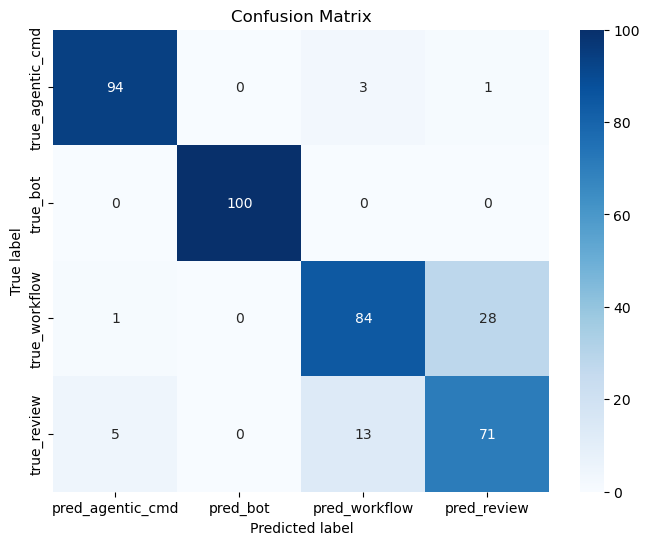

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

In [9]:
print(sum(m_bot))
print(len(pr_comments[m_comments]))

28004
11118


In [10]:
pr_comments['rev_type'].value_counts() / sum(m_comments)

rev_type
review         2.517539
agentic_cmd    0.753463
workflow       0.162349
bot            0.085447
Name: count, dtype: float64

In [11]:
sum(m_comments)

11118

In [12]:
pr_comments__human = pr_comments[m_comments]
pr_comments__human__counts = pr_comments__human['rev_type'].value_counts()
display(pr_comments__human__counts)
print(sum(m_comments))
len(pr_comments) - sum(m_comments)

rev_type
review         5778
agentic_cmd    3134
workflow       1417
bot             789
Name: count, dtype: int64

11118


28004

In [13]:
pr_comments[pr_comments['rev_type'] == 'bot']

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
339,3126788393,3269032263,buger,14009,User,2025-07-28T11:28:19Z,/review how do you feel about this changes? Ar...,bot
424,2875765090,3057825906,lindy65,13020833,User,2025-05-13T09:38:34Z,/spinwick create --env MM_FEATUREFLAGS_Experim...,bot
747,3121064306,3264933329,sre-ci-robot,56469371,User,2025-07-26T02:59:06Z,[APPROVALNOTIFIER] This PR is **NOT APPROVED**...,bot
752,3048720914,3212218608,coveralls,2354108,User,2025-07-08T12:23:06Z,\n[![Coverage Status](https://coveralls.io/bui...,bot
754,3060259699,3212218608,k8s-ci-robot,20407524,BotOther,2025-07-11T03:37:20Z,[APPROVALNOTIFIER] This PR is **APPROVED**\n\n...,bot
...,...,...,...,...,...,...,...,...
38814,2877718073,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:33:16Z,/bump-version type=minor,bot
38822,2877736008,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:37:23Z,/bump-version,bot
38825,2877745636,3060998787,theyueli,61070669,User,2025-05-13T19:40:27Z,"/bump-version type=patch changelog=""Add suppor...",bot
38827,2877751802,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:42:48Z,"/bump-version type=patch changelog=""Add suppor...",bot


In [14]:
display(pr_comments['pr_id'].unique())

array([3107321792, 3234660269, 3037457814, ..., 2761443934, 3047296744,
       2823956710], shape=(12975,))

In [15]:
pr_comments[(pr_comments['rev_type'] == 'review') & (pr_comments['user_type'] == 'User')]

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
2,2848667986,3037457814,wilsonccccc,6146503,User,2025-05-03T15:12:37Z,"Hi, thanks for sharing and contributing! Pleas...",review
4,3013998830,3132410695,razimantv,3823215,User,2025-06-27T18:16:05Z,Can you rebase it to the current master? Pleas...,review
7,2720368428,2915784381,nickskalkin,3934579,User,2025-03-13T08:30:47Z,Co-authored-by: Claude \r\n😁,review
9,2721609147,2915784381,damassi,236943,User,2025-03-13T15:09:45Z,> Actually rewrite that commit and remove me a...,review
15,3111630135,3256172444,nilo19,36728755,User,2025-07-24T01:13:29Z,If it's hard to review I can split it into mul...,review
...,...,...,...,...,...,...,...,...
39107,2564708592,2762228850,shreysingla11,62649026,User,2024-12-29T12:25:49Z,"### Code Review Summary\n\nOverall, this PR ma...",review
39110,2693663048,2890563538,joaomdmoura,667063,User,2025-03-03T08:52:22Z,Disclaimer: This review was made by a crew of ...,review
39113,2564173971,2761443934,joaomdmoura,667063,User,2024-12-28T04:37:43Z,Disclaimer: This review was made by a crew of ...,review
39118,2874995243,3047296744,retrogtx,76801862,User,2025-05-13T04:07:09Z,failing tests + does not solve the original is...,review


In [16]:
def pr_summary(labels):
    unique = set(labels)
    return str(unique)

pr_labels_comment = (
    pr_comments[(pr_comments['user_type'] == 'User')].groupby("pr_id")["rev_type"]
      .apply(pr_summary)
      .reset_index(name="pr_type")
)

In [17]:
counts_comment = pr_labels_comment["pr_type"].value_counts()
print(counts_comment)

pr_type
{'review'}                                      2364
{'agentic_cmd'}                                  887
{'workflow'}                                     434
{'agentic_cmd', 'review'}                        349
{'review', 'workflow'}                           326
{'bot'}                                          198
{'agentic_cmd', 'review', 'workflow'}            118
{'bot', 'review'}                                102
{'agentic_cmd', 'workflow'}                       80
{'agentic_cmd', 'bot'}                            60
{'agentic_cmd', 'bot', 'review'}                  40
{'bot', 'review', 'workflow'}                     29
{'agentic_cmd', 'bot', 'review', 'workflow'}      13
{'bot', 'workflow'}                               11
{'agentic_cmd', 'bot', 'workflow'}                 6
Name: count, dtype: int64


In [18]:
# No classical human part
print(counts_comment[~counts_comment.index.str.contains("review")].sum()/counts_comment.sum())

# Only clasical
clasical_filter = counts_comment.index.str.contains("{'review'}")
print(counts_comment[clasical_filter].sum()/counts_comment.sum())

# Classical + other
print(counts_comment[counts_comment.index.str.contains("review") & ~clasical_filter].sum()/counts_comment.sum())

0.3340641817819414
0.4711979270480367
0.19473789117002194


In [19]:
filtered_comments = pr_comments[
    (pr_comments["user_type"] == "User") &
    (pr_comments["rev_type"] == "review") 
]

top_bodies_comments = (
    filtered_comments["body"].str.lower()
    .value_counts()
    .head(50)     
)

#print(top_bodies_comments)

In [20]:
# Command for searching suspicious data
filtered_comments[filtered_comments['body'].str.lower().str.contains("")]

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
2,2848667986,3037457814,wilsonccccc,6146503,User,2025-05-03T15:12:37Z,"Hi, thanks for sharing and contributing! Pleas...",review
4,3013998830,3132410695,razimantv,3823215,User,2025-06-27T18:16:05Z,Can you rebase it to the current master? Pleas...,review
7,2720368428,2915784381,nickskalkin,3934579,User,2025-03-13T08:30:47Z,Co-authored-by: Claude \r\n😁,review
9,2721609147,2915784381,damassi,236943,User,2025-03-13T15:09:45Z,> Actually rewrite that commit and remove me a...,review
15,3111630135,3256172444,nilo19,36728755,User,2025-07-24T01:13:29Z,If it's hard to review I can split it into mul...,review
...,...,...,...,...,...,...,...,...
39107,2564708592,2762228850,shreysingla11,62649026,User,2024-12-29T12:25:49Z,"### Code Review Summary\n\nOverall, this PR ma...",review
39110,2693663048,2890563538,joaomdmoura,667063,User,2025-03-03T08:52:22Z,Disclaimer: This review was made by a crew of ...,review
39113,2564173971,2761443934,joaomdmoura,667063,User,2024-12-28T04:37:43Z,Disclaimer: This review was made by a crew of ...,review
39118,2874995243,3047296744,retrogtx,76801862,User,2025-05-13T04:07:09Z,failing tests + does not solve the original is...,review


In [21]:
slash_counts_comments = (
    pr_comments[pr_comments["body"].str.startswith("/", na=False) & (pr_comments["rev_type"] == 'review')]["body"].value_counts()
)
#print(slash_counts_comments)

In [22]:
mask_comments = pr_comments["body"].str.startswith("/", na=False) & (pr_comments["rev_type"] == "review")

# extract first token after '/'
first_word_comments = pr_comments.loc[mask_comments, "body"].str.extract(r"^/(\S+)", expand=False)

slash_counts_comments = first_word_comments.value_counts()

#print(slash_counts_comments)

In [23]:
pr_comments[pr_comments['rev_type'] == 'agentic_cmd']

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
0,2927293042,3107321792,coderabbitai[bot],136622811,Bot,2025-06-01T14:15:35Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
1,3090154270,3234660269,Fank,1900106,User,2025-07-18T17:22:34Z,"claude budget reached, development is on hold ...",agentic_cmd
14,3107769358,3256172444,coderabbitai[bot],136622811,Bot,2025-07-23T12:23:45Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
19,2991504795,3163243464,coderabbitai[bot],136622811,Bot,2025-06-20T12:56:07Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
21,3051526209,3214876564,coderabbitai[bot],136622811,Bot,2025-07-09T07:39:39Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
...,...,...,...,...,...,...,...,...
39059,2722820285,2918508503,coderabbitai[bot],136622811,Bot,2025-03-13T22:27:44Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
39062,2891388779,3073587664,devin-ai-integration[bot],158243242,Bot,2025-05-19T15:09:50Z,Devin is archived and cannot be woken up. Plea...,agentic_cmd
39068,2725444393,2920983723,coderabbitai[bot],136622811,Bot,2025-03-14T18:19:45Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
39089,2942423791,3119572928,devin-ai-integration[bot],158243242,Bot,2025-06-05T01:42:22Z,### 🤖 Devin AI Engineer\n\nI'll be helping wit...,agentic_cmd
